# Promotion Uplift: which products to promote, and where?

## 1. Data loading

In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from src.config import FEATURES, TARGET
from src.models import Baseline, SLearner, TLearner, make_gb, make_rf
from src.evaluation import compare_methods, real_uplift_by_decile, real_uplift_top_share, regression_metrics

path = "../data/raw/"

In [138]:
trans = pd.read_csv(path + "transaction_data.csv")
product = pd.read_csv(path + "product.csv")

# Load a sample of causal data to avoid reading the full dataset into memory because its very large
causal_sample = pd.read_csv(path + "causal_data.csv", nrows=100_000)

In [139]:
print(trans.shape, product.shape)

(2595732, 12) (92353, 7)


In [140]:
trans.head()

,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


In [141]:
product.head()

,PRODUCT_ID,MANUFACTURER,DEPARTMENT,BRAND,COMMODITY_DESC,SUB_COMMODITY_DESC,CURR_SIZE_OF_PRODUCT
0,25671,2,GROCERY,National,FRZN ICE,ICE - CRUSHED/CUBED,22 LB
1,26081,2,MISC. TRANS.,National,NO COMMODITY DESCRIPTION,NO SUBCOMMODITY DESCRIPTION,
2,26093,69,PASTRY,Private,BREAD,BREAD:ITALIAN/FRENCH,
3,26190,69,GROCERY,Private,FRUIT - SHELF STABLE,APPLE SAUCE,50 OZ
4,26355,69,GROCERY,Private,COOKIES/CONES,SPECIALTY COOKIES,14 OZ


In [142]:
causal_sample.head()

,PRODUCT_ID,STORE_ID,WEEK_NO,display,mailer
0,26190,286,70,0,A
1,26190,288,70,0,A
2,26190,289,70,0,A
3,26190,292,70,0,A
4,26190,293,70,0,A


## 2. Data description


**Source:** Dunnhumby – The Complete Journey (Kaggle). This dataset contains household level transactions over two years from a group of 2,500 households who are frequent shoppers at a retailer. 

**Tables used**
transaction_data : sales 
causal_data : promotion flags 
product : brand 

**Tables not used:** campaign, coupon and demographic tables are household-level,this poject first version works at product × store level.

**transaction_data**

| Column | Description |
|---|---|
| household_key | household (loyalty card) ID |
| BASKET_ID | BASKET ID (panier) |
| DAY / WEEK_NO | day (1–711) and week (1–102) of the study |
| PRODUCT_ID | product ID |
| STORE_ID | store ID |
| QUANTITY | units bought |
| SALES_VALUE | amount paid by the customer |
| RETAIL_DISC | store discount |
| COUPON_DISC / COUPON_MATCH_DISC | coupon discounts  |
| TRANS_TIME | time of purchase |

**causal_data**

| Column | Description |
|---|---|
| PRODUCT_ID, STORE_ID, WEEK_NO | - |
| display | in-store display location (binary) |
| mailer | placement in the weekly flyer (binary) |

**Promotion definition:** promoted = 1 if the product is on display or in the mailer that week.

**product**

| Column | Description |
|---|---|
| PRODUCT_ID | product ID |
| MANUFACTURER | manufacturer code |
| DEPARTMENT | top level of the product hierarchy  |
| COMMODITY_DESC | product category |
| SUB_COMMODITY_DESC | prodcut sub-category |
| BRAND | National (manufacturer brand) or Private (store brand) |
| CURR_SIZE_OF_PRODUCT | - |


## 3. Data quality checks

### 3.1 Transactions

#### Finding

In [144]:
trans.info() #check columns type
trans.isna().sum() #check missing values

<class 'pandas.DataFrame'>
RangeIndex: 2595732 entries, 0 to 2595731
Data columns (total 12 columns):
 #   Column             Dtype  
---  ------             -----  
 0   household_key      int64  
 1   BASKET_ID          int64  
 2   DAY                int64  
 3   PRODUCT_ID         int64  
 4   QUANTITY           int64  
 5   SALES_VALUE        float64
 6   STORE_ID           int64  
 7   RETAIL_DISC        float64
 8   TRANS_TIME         int64  
 9   WEEK_NO            int64  
 10  COUPON_DISC        float64
 11  COUPON_MATCH_DISC  float64
dtypes: float64(4), int64(8)
memory usage: 237.6 MB


household_key        0
BASKET_ID            0
DAY                  0
PRODUCT_ID           0
QUANTITY             0
SALES_VALUE          0
STORE_ID             0
RETAIL_DISC          0
TRANS_TIME           0
WEEK_NO              0
COUPON_DISC          0
COUPON_MATCH_DISC    0
dtype: int64

In [145]:
trans.duplicated().sum() #check duplicate values

np.int64(0)

In [146]:
trans[["QUANTITY", "SALES_VALUE", "RETAIL_DISC", "COUPON_DISC", "COUPON_MATCH_DISC"]].describe()

,QUANTITY,SALES_VALUE,RETAIL_DISC,COUPON_DISC,COUPON_MATCH_DISC
count,2.595732e+06,2.595732e+06,2.595732e+06,2.595732e+06,2.595732e+06
mean,1.004286e+02,3.104120e+00,-5.387054e-01,-1.641600e-02,-2.918564e-03
std,1.153436e+03,4.182274e+00,1.249191e+00,2.168410e-01,3.969004e-02
min,0.000000e+00,0.000000e+00,-1.800000e+02,-5.593000e+01,-7.700000e+00
25%,1.000000e+00,1.290000e+00,-6.900000e-01,0.000000e+00,0.000000e+00
50%,1.000000e+00,2.000000e+00,-1.000000e-02,0.000000e+00,0.000000e+00
75%,1.000000e+00,3.490000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,8.963800e+04,8.400000e+02,3.990000e+00,0.000000e+00,0.000000e+00


   - QUANTITY has extreme values: median 1, mean 100 but max 89638 .
   - Some rows have zero quantity or zero sales.
   - RETAIL_DISC should be ≤ 0, but a few values are positive.

In [ ]:
print("days:", trans["DAY"].min(), "-", trans["DAY"].max()) #min max days
print("weeks:", trans["WEEK_NO"].min(), "-", trans["WEEK_NO"].max()) #min max weeks
print("households:", trans["household_key"].nunique()) #nbr of unique values
print("stores:", trans["STORE_ID"].nunique())
print("products:", trans["PRODUCT_ID"].nunique())


days: 1 - 711
weeks: 1 - 102
households: 2500
stores: 582
products: 92339


With 582 stores and 92339 products, there are around 54 million possible combinations, but only 2.6 million transactions.

Many product-store pairs have limited sales history, making promotion effects difficult to measure. We will keep only pairs with regular sales.(to define later)

#### Investigating Transaction anomalies

In [147]:
# Anomaly 1: extreme quantities
big_qty = trans[trans["QUANTITY"] > 100].merge(product, on="PRODUCT_ID")
big_qty["COMMODITY_DESC"].value_counts().head(10)

COMMODITY_DESC
COUPON/MISC ITEMS    23129
FUEL                     6
CORN                     1
Name: count, dtype: int64

In [148]:
big_qty[["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]].value_counts().head(10)

DEPARTMENT       COMMODITY_DESC     SUB_COMMODITY_DESC   
KIOSK-GAS        COUPON/MISC ITEMS  GASOLINE-REG UNLEADED    20261
MISC SALES TRAN  COUPON/MISC ITEMS  GASOLINE-REG UNLEADED     2868
KIOSK-GAS        FUEL               GASOLINE-REG UNLEADED        6
PRODUCE          CORN               CORN WHITE                   1
Name: count, dtype: int64

23135 of the 23136 rows with quantity > 100 are gasoline (KIOSK-GAS / MISC SALES TRAN), sold at the fuel kiosk, not grocery products, so we exclude them. 

In [150]:
#Anomalies 2 and 3: zero values and positive discounts
print("nbr of zero quantities :", (trans["QUANTITY"] == 0).sum())
print("nbr of zero sales:", (trans["SALES_VALUE"] == 0).sum())
print("nbr of positive retail discount:", (trans["RETAIL_DISC"] > 0).sum())

nbr of zero quantities : 14466
nbr of zero sales: 18850
nbr of positive retail discount: 36


14466 rows (0.56%) with zero quantity and 18,850 rows (0.73%) with zero sales, so we will remove them. 36 rows with positive retail discount (should be ≤ 0), also removed.

### 3.2 Products

In [151]:
print((product["COMMODITY_DESC"] == "NO COMMODITY DESCRIPTION").sum()) #missing values
print((product["SUB_COMMODITY_DESC"] == "NO SUBCOMMODITY DESCRIPTION").sum()) #missing values
print((product["CURR_SIZE_OF_PRODUCT"].str.strip() == "").sum()) #missing values

490
429
30607


In [ ]:
product["DEPARTMENT"].value_counts() #thhe count of the products in each department

DEPARTMENT
GROCERY            39021
DRUG GM            31529
PRODUCE             3118
COSMETICS           3011
NUTRITION           2914
MEAT                2544
MEAT-PCKGD          2427
DELI                2354
PASTRY              2149
FLORAL               938
SEAFOOD-PCKGD        563
MISC. TRANS.         490
SPIRITS              377
SEAFOOD              369
GARDEN CENTER        128
RESTAURANT           102
MISC SALES TRAN       88
SALAD BAR             48
COUP/STR & MFG        39
TRAVEL & LEISUR       28
FROZEN GROCERY        23
KIOSK-GAS             16
                      15
CHEF SHOPPE           14
RX                     9
CNTRL/STORE SUP        4
GM MERCH EXP           3
TOYS                   3
DAIRY DELI             3
VIDEO RENTAL           3
POSTAL CENTER          3
GRO BAKERY             2
CHARITABLE CONT        2
PROD-WHS SALES         2
DELI/SNACK BAR         2
AUTOMOTIVE             2
PHOTO                  2
VIDEO                  2
ELECT &PLUMBING        1
MEAT-WHSE     

In [ ]:
product["BRAND"].value_counts() #the count of products in each branch

BRAND
National    78537
Private     13816
Name: count, dtype: int64

In [152]:
missing = ~trans["PRODUCT_ID"].isin(product["PRODUCT_ID"]) #some products in transaction table but they are missing in product table
print("transaction lines with unknown product:", missing.sum())

transaction lines with unknown product: 0


- 490 products with "NO COMMODITY DESCRIPTION"
- Size is empty for 33% of products, so it is not used as columns.
- Main departments: GROCERY and DRUG GM. 
Non-merchandise departments (KIOSK-GAS, MISC SALES TRAN, MISC. TRANS., COUP/STR & MFG, TRAVEL & LEISUR, empty) are excluded.
- All transaction products exist in the product table, the join is safe.

### 3.3 Promotions


In [106]:
causal_sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   PRODUCT_ID  100000 non-null  int64
 1   STORE_ID    100000 non-null  int64
 2   WEEK_NO     100000 non-null  int64
 3   display     100000 non-null  str  
 4   mailer      100000 non-null  str  
dtypes: int64(3), str(2)
memory usage: 3.8 MB


In [ ]:
print("weeks:", causal_sample["WEEK_NO"].min(), "-", causal_sample["WEEK_NO"].max()) #min max weeks
print("stores:", causal_sample["STORE_ID"].nunique()) #unique nbr of stores
print(causal_sample["display"].value_counts()) #count of display promo
print(causal_sample["mailer"].value_counts()) #count of flyer promo

weeks: 9 - 101
stores: 115
display
0    54588
7    11170
9     8387
2     6070
5     5839
3     5368
A     3165
6     2992
1     1541
4      880
Name: count, dtype: int64
mailer
A    43303
0    30317
D    20831
H     4366
J      453
F      428
C      302
Name: count, dtype: int64


- Promotion data covers weeks 9–101 only, (trans covered data from 1), so when modeling we  will useuses weeks 9–101.

- Assumption: we will consider a product × store × week in transa and missing from causal_data as not promoted.


### 3.4 Summary of issues and decisions


| # | Issue | Size | Decision |
|---|---|---|---|
| 1 | Extreme quantities  | ~23k rows | exclude fuel departments |
| 2 | Zero quantity or zero sales | ~14k / ~19k rows (< 1%) | remove |
| 3 | Positive retail discount | 36 rows | remove |
| 4 | Sparse product × store pairs | most pairs | keep pairs with regular sales, threshold will be computed on training  (avoid leakage) |
| 5 | Non-merchandise departments (fuel, misc, coupons, travel, empty) | few products | exclude |
| 6 | Empty product size | 33% of products | column not used |
| 7 | Promotion data only for weeks 9–101 | weeks 1–8 and 102 missing | weeks 1–8 and 102 not modeled |
| 9 | causal_data lists only promoted items | 0 "not promoted" rows | absent = not promoted |


## 4. Data preparation

Steps:
1. Clean transactions 
2. Load the full promotion table and create promotion flags
3. Aggregate sales to product × store × week
4. Keep stores with promotion data and weeks 9–101
5. Merge sales and promotions (missing promotion = not promoted)

### 4.1 Cleaning transactions

In [108]:
non_merch = ["KIOSK-GAS", "MISC SALES TRAN", "MISC. TRANS.", "COUP/STR & MFG", "TRAVEL & LEISUR", " "]
non_merch_products = product.loc[product["DEPARTMENT"].str.strip().isin([d.strip() for d in non_merch]), "PRODUCT_ID"]

n_before = len(trans)

clean = trans[~trans["PRODUCT_ID"].isin(non_merch_products)]
clean = clean[(clean["QUANTITY"] > 0) & (clean["SALES_VALUE"] > 0)]
clean = clean[clean["RETAIL_DISC"] <= 0]

print("rows before:", n_before)
print("rows after:", len(clean))
print("removed:", n_before - len(clean), f"({(n_before - len(clean)) / n_before:.1%})")

rows before: 2595732
rows after: 2545250
removed: 50482 (1.9%)


Cleaning removed 50482 rows (1.9%)

### 4.2 Promotion flags

In [153]:
causal = pd.read_csv(
    path + "causal_data.csv",
    dtype={"PRODUCT_ID": "int32", "STORE_ID": "int32", "WEEK_NO": "int8",
           "display": "category", "mailer": "category"}
)
print(causal.shape)


(36786524, 5)


In [154]:
causal["on_display"] = (causal["display"] != "0").astype("int8")
causal["in_mailer"] = (causal["mailer"] != "0").astype("int8")
causal = causal.drop(columns=["display", "mailer"])

print("weeks:", causal["WEEK_NO"].min(), "-", causal["WEEK_NO"].max())
print("stores:", causal["STORE_ID"].nunique())
print(causal[["on_display", "in_mailer"]].mean())

weeks: 9 - 101
stores: 115
on_display    0.428086
in_mailer     0.686456
dtype: float64


In [156]:
keys = ["PRODUCT_ID", "STORE_ID", "WEEK_NO"]
print("duplicate keys in causal:", causal.duplicated(subset=keys).sum())

causal_unique = causal.groupby(keys)[["on_display", "in_mailer"]].max().reset_index()
print(len(causal), "=>", len(causal_unique))

duplicate keys in causal: 15245
36786524 => 36771279


causal_data contains 15245 duplicate product × store × week keys (0.04%), so we delete duplications

### 4.3 Weekly sales per product × store

In [112]:
weekly = (
    clean.groupby(["PRODUCT_ID", "STORE_ID", "WEEK_NO"])
    .agg(sales=("SALES_VALUE", "sum"),
         quantity=("QUANTITY", "sum"),
         retail_disc=("RETAIL_DISC", "sum"),
         n_baskets=("BASKET_ID", "nunique"))
    .reset_index()
)
print(weekly.shape)
weekly.head()

(2342342, 7)


,PRODUCT_ID,STORE_ID,WEEK_NO,sales,quantity,retail_disc,n_baskets
0,25671,3191,59,13.96,4,0.0,1
1,25671,3266,36,3.49,1,0.0,1
2,25671,3313,23,3.49,1,0.0,1
3,26093,33904,66,1.59,1,0.0,1
4,26190,3297,35,1.54,1,0.0,1


### 4.4 Restricting to stores with promotion data

In [113]:
promo_stores = causal["STORE_ID"].unique()
weekly = weekly[weekly["STORE_ID"].isin(promo_stores)]
print("rows:", len(weekly))
print("stores:", weekly["STORE_ID"].nunique())
print("product x store pairs:", weekly.groupby(["PRODUCT_ID", "STORE_ID"]).ngroups)

rows: 2306601
stores: 115
product x store pairs: 905738


In [159]:
for n in [10, 15, 20, 30, 50]:
    print(f"pairs sold in at least {n} weeks:", (weeks_per_pair >= n).sum())

pairs sold in at least 10 weeks: 34241
pairs sold in at least 15 weeks: 16872
pairs sold in at least 20 weeks: 9853
pairs sold in at least 30 weeks: 4281
pairs sold in at least 50 weeks: 1109


**Checking the promotion assumption** (full data)

In [116]:
both_zero = ((causal["on_display"] == 0) & (causal["in_mailer"] == 0)).sum()
print("rows in causal with no display and no mailer:", both_zero)

rows in causal with no display and no mailer: 0


In [117]:
check = weekly.merge(causal, on=["PRODUCT_ID", "STORE_ID", "WEEK_NO"], how="left")
print("share of weekly sales rows found in causal:", check["on_display"].notna().mean())

share of weekly sales rows found in causal: 0.20840320472951154


causal_data contains only promoted rows (0 rows with neither display nor mailer). A product × store × week absent from causal_data is  treated as not promoted .

we will keep only 9,853 pairs sell in ≥ 15 weeks. Decision: keep product × store pairs with ≥ 20 selling weeks (threshold applied on training weeks only, after the split (leakage)).

## 5. Validation strategy (time split)

Promotion data covers weeks 9–101. Weeks 1–8 have no promotion data, so they are not modeled.
History features (past sales and past promotions) look back up to 4 weeks, so weeks 9–12 are only used as history, and modeling starts at week 13:
- train: weeks 13–71
- validation: weeks 72–86 
- test: weeks 87–101 

In [158]:
TRAIN_START = 13  # train = weeks 13 to 71 (weeks 9-12 used only as history)
VALID_WEEK = 72   # validation = weeks 72 to 86
SPLIT_WEEK = 87   # test = weeks 87 to 101

## 6. Building the modeling table

### 6.1 Selection of regular pairs


In [160]:
past_weeks = weekly[weekly["WEEK_NO"] < VALID_WEEK]
weeks_per_pair_train = past_weeks.groupby(["PRODUCT_ID", "STORE_ID"])["WEEK_NO"].nunique()

regular_pairs = weeks_per_pair_train[weeks_per_pair_train >= 15].index
print("regular pairs (based on training weeks < 72):", len(regular_pairs))

regular pairs (based on training weeks < 72): 8831


The "regular pairs" filter  is computed on training weeks only (< 72), so neither validation nor test data influences which pairs are kept.

### 6.2 Complete weekly grid + promotions


For each regular pair, we create one row per week (1–101), including weeks with no sales (sales = 0). Then we attach the promotion flags.

In [161]:
pairs = regular_pairs.to_frame(index=False)
weeks = pd.DataFrame({"WEEK_NO": range(1, 102)})
grid = pairs.merge(weeks, how="cross")

data = grid.merge(weekly, on=keys, how="left")
data[["sales", "quantity", "retail_disc", "n_baskets"]] = data[["sales", "quantity", "retail_disc", "n_baskets"]].fillna(0)

print(data.shape)
print("share of weeks with zero sales:", (data["sales"] == 0).mean())

(891931, 7)
share of weeks with zero sales: 0.6755186219561827


In [162]:
n_before = len(data)
data = data.merge(causal_unique, on=keys, how="left")
print("rows unchanged after merge:", len(data) == n_before)

data[["on_display", "in_mailer"]] = data[["on_display", "in_mailer"]].fillna(0).astype(int)
data["promoted"] = ((data["on_display"] == 1) | (data["in_mailer"] == 1)).astype(int)

print("share of promoted weeks:", data.loc[data["WEEK_NO"] >= 9, "promoted"].mean())

rows unchanged after merge: True
share of promoted weeks: 0.2204964671130414


Modeling table: 891931 rows. 22% of weeks (from week 9) are promoted.

### 6.3 Adding product information

In [163]:
n_before = len(data)
data = data.merge(product[["PRODUCT_ID", "DEPARTMENT", "COMMODITY_DESC", "BRAND"]], on="PRODUCT_ID", how="left")
print("rows unchanged after merge:", len(data) == n_before)

print("departments:", data["DEPARTMENT"].nunique())
print("categories:", data["COMMODITY_DESC"].nunique())
data["DEPARTMENT"].value_counts().head(10)

rows unchanged after merge: True
departments: 14
categories: 177


DEPARTMENT
GROCERY       551359
PRODUCE       199475
DRUG GM        36057
MEAT           32522
DELI           30199
MEAT-PCKGD     19493
PASTRY          9494
SALAD BAR       8585
NUTRITION       2828
SPIRITS          606
Name: count, dtype: int64

After filtering, the studied products are mainly GROCERY (62%) and PRODUCE (22%)

## 7. Feature engineering

Weeks 1–8 are dropped (promotion status unknown). For each row, features describe only the past weeks of the same product × store:
- sales_lag1: sales of previous week, sales_lag2: sales 2 weeks before
- sales_avg4: average sales over the 4 previous weeks
- sales_avg_past: average sales over all previous weeks 
- promo_lag1: promoted the previous week
- promo_count4: number of promoted weeks among the 4 previous weeks

In [164]:
data = data[data["WEEK_NO"] >= 9]
data = data.sort_values(["PRODUCT_ID", "STORE_ID", "WEEK_NO"]).reset_index(drop=True)

g = data.groupby(["PRODUCT_ID", "STORE_ID"])

data["sales_lag1"] = g["sales"].shift(1)
data["sales_lag2"] = g["sales"].shift(2)
data["sales_avg4"] = g["sales"].transform(lambda s: s.shift(1).rolling(4).mean())
data["sales_avg_past"] = g["sales"].transform(lambda s: s.shift(1).expanding().mean())
data["promo_lag1"] = g["promoted"].shift(1)
data["promo_count4"] = g["promoted"].transform(lambda s: s.shift(1).rolling(4).sum())

data = data[data["WEEK_NO"] >= TRAIN_START]
print(data.shape)
data.isna().sum()

(785959, 19)


PRODUCT_ID        0
STORE_ID          0
WEEK_NO           0
sales             0
quantity          0
retail_disc       0
n_baskets         0
on_display        0
in_mailer         0
promoted          0
DEPARTMENT        0
COMMODITY_DESC    0
BRAND             0
sales_lag1        0
sales_lag2        0
sales_avg4        0
sales_avg_past    0
promo_lag1        0
promo_count4      0
dtype: int64

Final modeling table: 785959 rows , no missing values. All history features use only past weeks of the same product × store (no leakage).

In [165]:
train = data[data["WEEK_NO"] < VALID_WEEK]
valid = data[(data["WEEK_NO"] >= VALID_WEEK) & (data["WEEK_NO"] < SPLIT_WEEK)]
test = data[data["WEEK_NO"] >= SPLIT_WEEK]

for name, df in [("train", train), ("valid", valid), ("test", test)]:
    print(name, df.shape, "weeks", df["WEEK_NO"].min(), "-", df["WEEK_NO"].max(),
          "| promoted share:", round(df["promoted"].mean(), 3))

train (521029, 19) weeks 13 - 71 | promoted share: 0.225
valid (132465, 19) weeks 72 - 86 | promoted share: 0.216
test (132465, 19) weeks 87 - 101 | promoted share: 0.206


## 8. Exploratory data analysis (on train)

EDA is done on the training period only, so that validation and test data do not influence modeling choices.

### 8.1 Do promoted weeks sell more?

In [125]:
summary = train.groupby("promoted").agg(
    rows=("sales", "size"),
    avg_sales=("sales", "mean"),
    zero_share=("sales", lambda s: (s == 0).mean())
)
summary

,rows,avg_sales,zero_share
promoted,,,
0,403831,1.128703,0.657421
1,117198,1.812420,0.515922


comparison on train: promoted weeks average $1.81 vs $1.13 for non-promoted (+61%), and are less often zero (52% vs 66%)

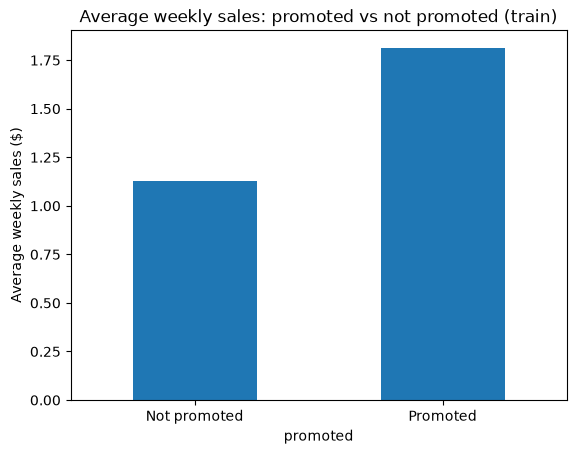

In [126]:
summary["avg_sales"].plot(kind="bar")
plt.xticks([0, 1], ["Not promoted", "Promoted"], rotation=0)
plt.ylabel("Average weekly sales ($)")
plt.title("Average weekly sales: promoted vs not promoted (train)")
plt.show()

### 8.2 Which promotion type works best: display, mailer, or both?

In [166]:
train = train.copy()
train["promo_type"] = "none"
train.loc[(train["on_display"] == 1) & (train["in_mailer"] == 0), "promo_type"] = "display only"
train.loc[(train["on_display"] == 0) & (train["in_mailer"] == 1), "promo_type"] = "mailer only"
train.loc[(train["on_display"] == 1) & (train["in_mailer"] == 1), "promo_type"] = "both"

by_type = train.groupby("promo_type").agg(
    rows=("sales", "size"),
    avg_sales=("sales", "mean")
)
by_type["vs_none_%"] = (by_type["avg_sales"] / by_type.loc["none", "avg_sales"] - 1) * 100
by_type.sort_values("avg_sales")

,rows,avg_sales,vs_none_%
promo_type,,,
none,403831,1.128703,0.000000
display only,38191,1.351836,19.768904
both,24726,2.000360,77.226420
mailer only,54281,2.050868,81.701216


mailer only +82%, both +77%, display only +20% vs no promotion. The mailer is the strongest

### 8.3 Selection bias: are promoted products already strong sellers?

In [167]:
train.groupby("promoted")["sales_avg_past"].mean()

promoted
0    1.087983
1    1.198479
Name: sales_avg_past, dtype: float64

In [168]:
pair_means = train.groupby(["PRODUCT_ID", "STORE_ID", "promoted"])["sales"].mean().unstack()
pair_means = pair_means.dropna()

print("pairs with both promoted and non-promoted weeks:", len(pair_means))
print("avg sales not promoted:", pair_means[0].mean())
print("avg sales promoted:", pair_means[1].mean())
print("within-pair uplift %:", (pair_means[1].mean() / pair_means[0].mean() - 1) * 100)

pairs with both promoted and non-promoted weeks: 7138
avg sales not promoted: 1.0932662476029646
avg sales promoted: 1.7635504662342307
within-pair uplift %: 61.31024534059242


- Promoted products already had slightly higher sales before promotion ($1.20 vs $1.09), showing some selection bias.
- Comparing each product-store pair with itself (7,138 pairs) gives a similar uplift: $1.76 vs $1.09 (+61%).
- This suggests product selection explains little of the sales gap.

## 9. Modeling

Goal: predict weekly sales with and without promotion; uplift = difference.
Models are compared on the validation set ; the test set is used once at the end .

### 9.1 Features and target

- Target: weekly sales ($) of a product × store.
- Features: promoted, sales_lag1, sales_lag2, sales_avg4, sales_avg_past, promo_lag1, promo_count4, DEPARTMENT, BRAND.

In [ ]:

for col in ["DEPARTMENT", "BRAND"]:
    cats = sorted(data[col].unique())
    for df in [train, valid, test]:
        df[col] = pd.Categorical(df[col], categories=cats)

### 9.2 Methods compared

- Baseline: pair's normal level (sales_avg_past) × average within-pair uplift measured on train (8.3): the same % uplift for every pair.
- S-learner: one model with "promoted" as a feature, predicted twice (promoted = 1 / 0); uplift = difference.
- T-learner: two models, one trained on promoted weeks, one on non-promoted weeks; uplift = difference of their predictions.
- Two algorithm families:
  - Gradient boosting 
  - Random Forest 

### 9.3 Comparison on validation


In [132]:
methods = {
    "Baseline": Baseline(),
    "S-learner GB": SLearner(make_gb),
    "T-learner GB": TLearner(make_gb),
    "S-learner RF": SLearner(make_rf),
    "T-learner RF": TLearner(make_rf),
}
comparison, uplifts = compare_methods(methods, train, valid)
comparison.round(3)

,MAE_train,MAE_valid,RMSE_valid,uplift_top10,uplift_top20
Baseline,1.472,1.455,2.383,1.922,1.563
S-learner GB,1.438,1.374,2.269,2.774,2.187
T-learner GB,1.427,1.373,2.269,2.810,2.080
S-learner RF,1.431,1.373,2.267,2.677,2.144
T-learner RF,1.431,1.372,2.266,2.751,2.191


All four models reach the same accuracy (validation MAE 1.372–1.374 vs 1.455 for the baseline, −5.6%), with no overfitting (train and validation errors are close).
For ranking, all models clearly beat the baseline (real uplift in the top 10%: 2.68–2.81 vs 1.92; top 20%: 2.08–2.19 vs 1.56). 


### 9.4 Uplift evaluation

Real uplift (measured on validation sales) per decile of predicted uplift, and for the top X% of rows selected by each method.

In [133]:
deciles = pd.DataFrame({name: real_uplift_by_decile(u, valid) for name, u in uplifts.items()})
deciles.round(2)

,Baseline,S-learner GB,T-learner GB,S-learner RF,T-learner RF
decile,,,,,
1,0.07,-0.03,-0.01,0.02,-0.02
2,0.16,0.26,0.16,0.30,0.31
3,0.20,0.29,0.28,0.40,0.38
4,0.32,0.40,0.36,0.52,0.43
5,0.28,0.45,0.49,0.51,0.52
6,0.31,0.55,0.52,0.54,0.56
7,0.45,0.62,0.61,0.61,0.56
8,0.60,0.83,0.83,0.90,0.80
9,1.04,1.31,1.12,1.34,1.35


For all methods, the real uplift increases from the lowest to the highest decile of predicted uplift

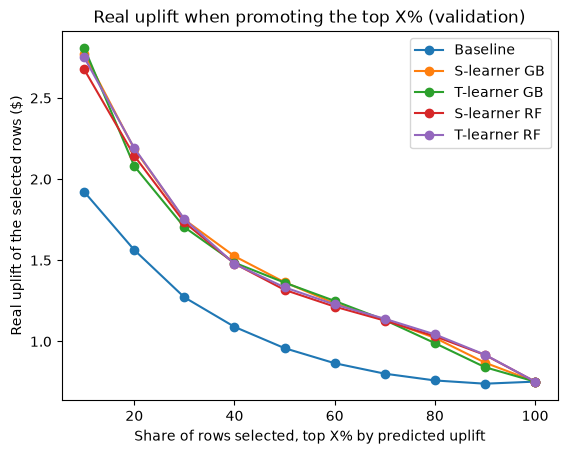

,Baseline,S-learner GB,T-learner GB,S-learner RF,T-learner RF
10,1.92,2.77,2.81,2.68,2.75
20,1.56,2.19,2.08,2.14,2.19
30,1.27,1.75,1.70,1.73,1.75
40,1.09,1.53,1.48,1.48,1.48
50,0.96,1.36,1.36,1.32,1.33
60,0.87,1.23,1.25,1.21,1.23
70,0.80,1.13,1.13,1.13,1.14
80,0.76,1.02,0.99,1.03,1.04
90,0.74,0.87,0.84,0.92,0.92
100,0.75,0.75,0.75,0.75,0.75


In [134]:
cumulative = pd.DataFrame({name: real_uplift_top_share(u, valid) for name, u in uplifts.items()})
cumulative.plot(marker="o")
plt.xlabel("Share of rows selected, top X% by predicted uplift")
plt.ylabel("Real uplift of the selected rows ($)")
plt.title("Real uplift when promoting the top X% (validation)")
plt.show()
cumulative.round(2)

Whatever the share of rows selected (10% to 90%), the rows chosen by any of the four models have a clearly higher real uplift than those chosen by the baseline . The four models are practically indistinguishable.

### 9.5 Model choice

### 9.5 Model choice

| Criterion | Result |
|---|---|
| Accuracy | All four models tied, all better than the baseline  |
| Overfitting | None  |
| Uplift ranking | All four models practically indistinguishable |
| Simplicity / speed | S-learner GB |

**Selected model: S-learner with gradient boosting.** Since the four models perform the same on accuracy and ranking, the simplest and fastest one is chosen. 

## 10. Final evaluation on the test set

The chosen model is retrained on train + validation, then evaluated once on the test set

In [171]:
train_full = pd.concat([train, valid])

for col in ["DEPARTMENT", "BRAND"]:
    cats = sorted(data[col].unique())
    train_full[col] = pd.Categorical(train_full[col], categories=cats)
    test[col] = pd.Categorical(test[col], categories=cats)

final_model = SLearner(make_gb).fit(train_full)
baseline = Baseline().fit(train_full)

test_metrics = pd.DataFrame({
    "Baseline": regression_metrics(test[TARGET], baseline.predict(test)),
    "S-learner GB": regression_metrics(test[TARGET], final_model.predict(test)),
}).T
test_metrics.round(3)

,MAE,RMSE
Baseline,1.419,2.377
S-learner GB,1.298,2.254


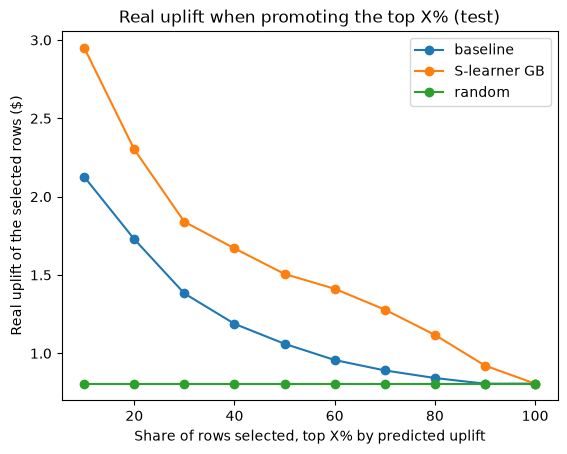

,baseline,S-learner GB,random
10,2.13,2.95,0.81
20,1.73,2.30,0.81
30,1.38,1.84,0.81
40,1.19,1.67,0.81
50,1.06,1.51,0.81
60,0.96,1.41,0.81
70,0.89,1.28,0.81
80,0.84,1.12,0.81
90,0.81,0.92,0.81
100,0.81,0.81,0.81


In [172]:
test_uplift = final_model.uplift(test)
random_level = test.loc[test["promoted"] == 1, TARGET].mean() - test.loc[test["promoted"] == 0, TARGET].mean()

test_cumulative = pd.DataFrame({
    "baseline": real_uplift_top_share(baseline.uplift(test), test),
    "S-learner GB": real_uplift_top_share(test_uplift, test),
})
test_cumulative["random"] = random_level

test_cumulative.plot(marker="o")
plt.xlabel("Share of rows selected, top X% by predicted uplift")
plt.ylabel("Real uplift of the selected rows ($)")
plt.title("Real uplift when promoting the top X% (test)")
plt.show()
test_cumulative.round(2)